# Task 3 — jabłka i pomidory: analiza danych i segmentacja
Celem jest sprawdzenie, czy usunięcie tła ułatwi późniejszą klasyfikację. Zachowujemy oryginalny podział train/test. Parametry i przykłady segmentacji dobieramy wyłącznie na train. Nie ma masek wzorcowych, więc nie można podać wiarygodnego IoU/Dice.

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import cv2
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'apples_tomatoes').exists() else Path.cwd() / 'third_task'
DATA = ROOT / 'apples_tomatoes'
OUT = ROOT / 'outputs'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110})
SEED = 42
def read_rgb(path):
    with Image.open(path) as im:
        return np.array(ImageOps.exif_transpose(im).convert('RGB'))


## 1. Inwentaryzacja i kontrola jakości

label,apples,tomatoes
split,,
test,54,43
train,164,130


width             height             mean_brightness            \
                 min median  max    min median  max             min    median   
split label                                                                     
test  apples     100  223.5  300    100  194.0  272        0.174471  0.687817   
      tomatoes   100  225.0  329    100  183.0  275        0.248331  0.437654   
train apples     100  225.0  318    100  194.0  283        0.206796  0.713827   
      tomatoes   100  225.0  335    100  183.0  275        0.250006  0.490871   

                          
                     max  
split label               
test  apples    0.902591  
      tomatoes  0.889199  
train apples    0.937399  
      tomatoes  0.949702

Obrazy: 391 | Błędy odczytu: 0
Rozdzielczości: {(100, 100): 98, (150, 150): 2, (159, 159): 16, (176, 177): 2, (177, 118): 4, (177, 133): 2, (177, 176): 2, (178, 283): 1, (180, 180): 1, (183, 275): 6, (183, 276): 1, (185, 272): 1, (186, 271): 1, (187, 269): 1, (187, 270): 1, (194, 259): 6, (194, 260): 1, (195, 258): 1, (196, 196): 6, (197, 255): 1, (201, 250): 1, (206, 245): 1, (208, 242): 1, (210, 240): 1, (212, 237): 1, (215, 143): 2, (215, 234): 1, (216, 233): 5, (218, 231): 2, (219, 230): 1, (220, 229): 3, (221, 228): 1, (223, 226): 2, (224, 224): 4, (224, 225): 3, (225, 224): 3, (225, 225): 88, (227, 222): 3, (228, 221): 1, (229, 220): 1, (230, 219): 1, (231, 218): 1, (234, 215): 1, (236, 214): 1, (237, 213): 1, (238, 212): 1, (240, 210): 1, (242, 208): 1, (243, 207): 1, (245, 205): 1, (248, 204): 1, (249, 202): 1, (251, 201): 2, (252, 200): 1, (255, 198): 1, (258, 195): 2, (259, 194): 16, (259, 195): 2, (260, 194): 2, (261, 193): 1, (262, 192): 2, (264, 191): 2, (266, 189): 2, (26

,split,label,path
10,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
11,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
12,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
13,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
14,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
16,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
42,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
44,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
50,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...
51,test,apples,/Users/manoftheprincess/Helloworld/Uni/agh/sem...


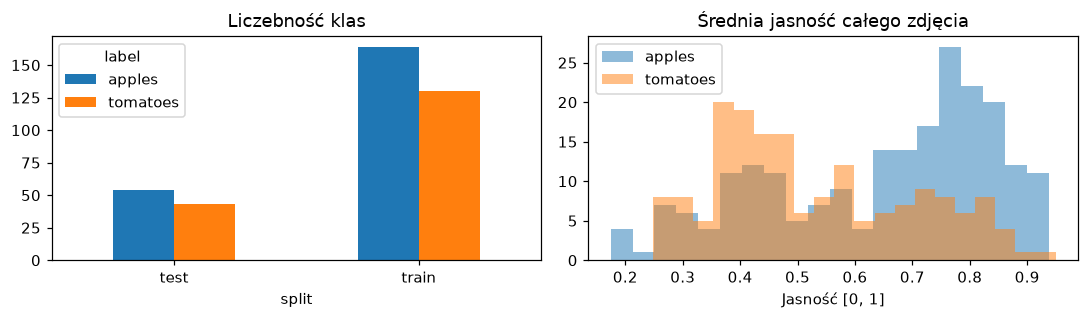

In [2]:
rows, errors = [], []
for path in sorted(DATA.rglob('*')):
    if not path.is_file(): continue
    try:
        rgb = read_rgb(path)
        rows.append(dict(path=str(path), split=path.relative_to(DATA).parts[0],
                         label=path.parent.name, width=rgb.shape[1], height=rgb.shape[0],
                         bytes=path.stat().st_size,
                         sha256=hashlib.sha256(path.read_bytes()).hexdigest(),
                         pixel_hash=hashlib.sha256(str(rgb.shape).encode()+rgb.tobytes()).hexdigest(),
                         mean_brightness=float(rgb.mean()/255)))
    except Exception as exc:
        errors.append((str(path), str(exc)))
df = pd.DataFrame(rows)
counts = pd.crosstab(df['split'], df['label'])
display(counts)
display(df.groupby(['split','label'])[['width','height','mean_brightness']].agg(['min','median','max']))
print('Obrazy:', len(df), '| Błędy odczytu:', len(errors))
print('Rozdzielczości:', df.groupby(['width','height']).size().to_dict())
print('Nadmiarowe identyczne pliki:', df.sha256.duplicated().sum())
print('Nadmiarowe identyczne obrazy:', df.pixel_hash.duplicated().sum())
leak = df.groupby('pixel_hash').filter(lambda g: g['split'].nunique() > 1)
print('Obrazy występujące w obu splitach:', len(leak))
display(leak[['split','label','path']])
if errors: display(errors)
df.to_csv(OUT / 'dataset_inventory.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(10,3))
counts.plot.bar(ax=axes[0], rot=0, title='Liczebność klas')
for label, g in df.groupby('label'):
    axes[1].hist(g.mean_brightness, bins=20, alpha=.5, label=label)
axes[1].set(title='Średnia jasność całego zdjęcia', xlabel='Jasność [0, 1]')
axes[1].legend(); plt.tight_layout(); plt.show()


## 2. Przykłady danych treningowych
Stałe losowanie po klasach pokazuje zróżnicowanie obiektów, oświetlenia i tła.

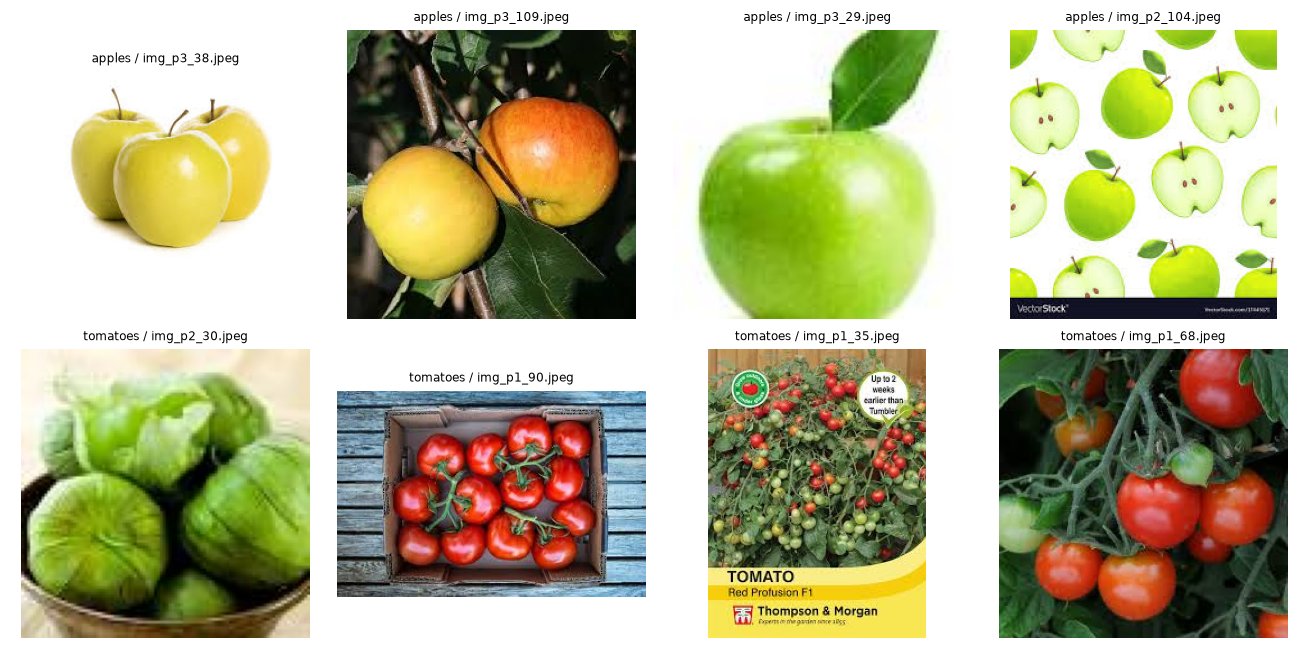

In [3]:
train = df[df.split == 'train'].copy()
examples = pd.concat([g.sample(min(4,len(g)), random_state=SEED) for _,g in train.groupby('label')])
fig, axes = plt.subplots(2,4,figsize=(12,6))
for ax, row in zip(axes.flat, examples.itertuples()):
    ax.imshow(read_rgb(row.path)); ax.set_title(f'{row.label} / {Path(row.path).name}', fontsize=8); ax.axis('off')
plt.tight_layout(); plt.savefig(OUT/'dataset_examples.png', bbox_inches='tight'); plt.show()


## 3. Segmentacja bez etykiet masek
Porównujemy dwa proste warianty: próg nasycenia HSV (kolorowy owoc kontra mało nasycone tło) oraz odległość koloru od tła oszacowanego z brzegu obrazu w przestrzeni Lab z progiem Otsu. Oba warianty czyszczą maskę morfologicznie, zostawiają największy obszar i wypełniają jego wnętrze. To zakłada jeden główny owoc na zdjęciu. Wypełnienie może usunąć prawdziwe otwory, a największy obszar może być fragmentem tła — oglądamy także trudne przypadki.

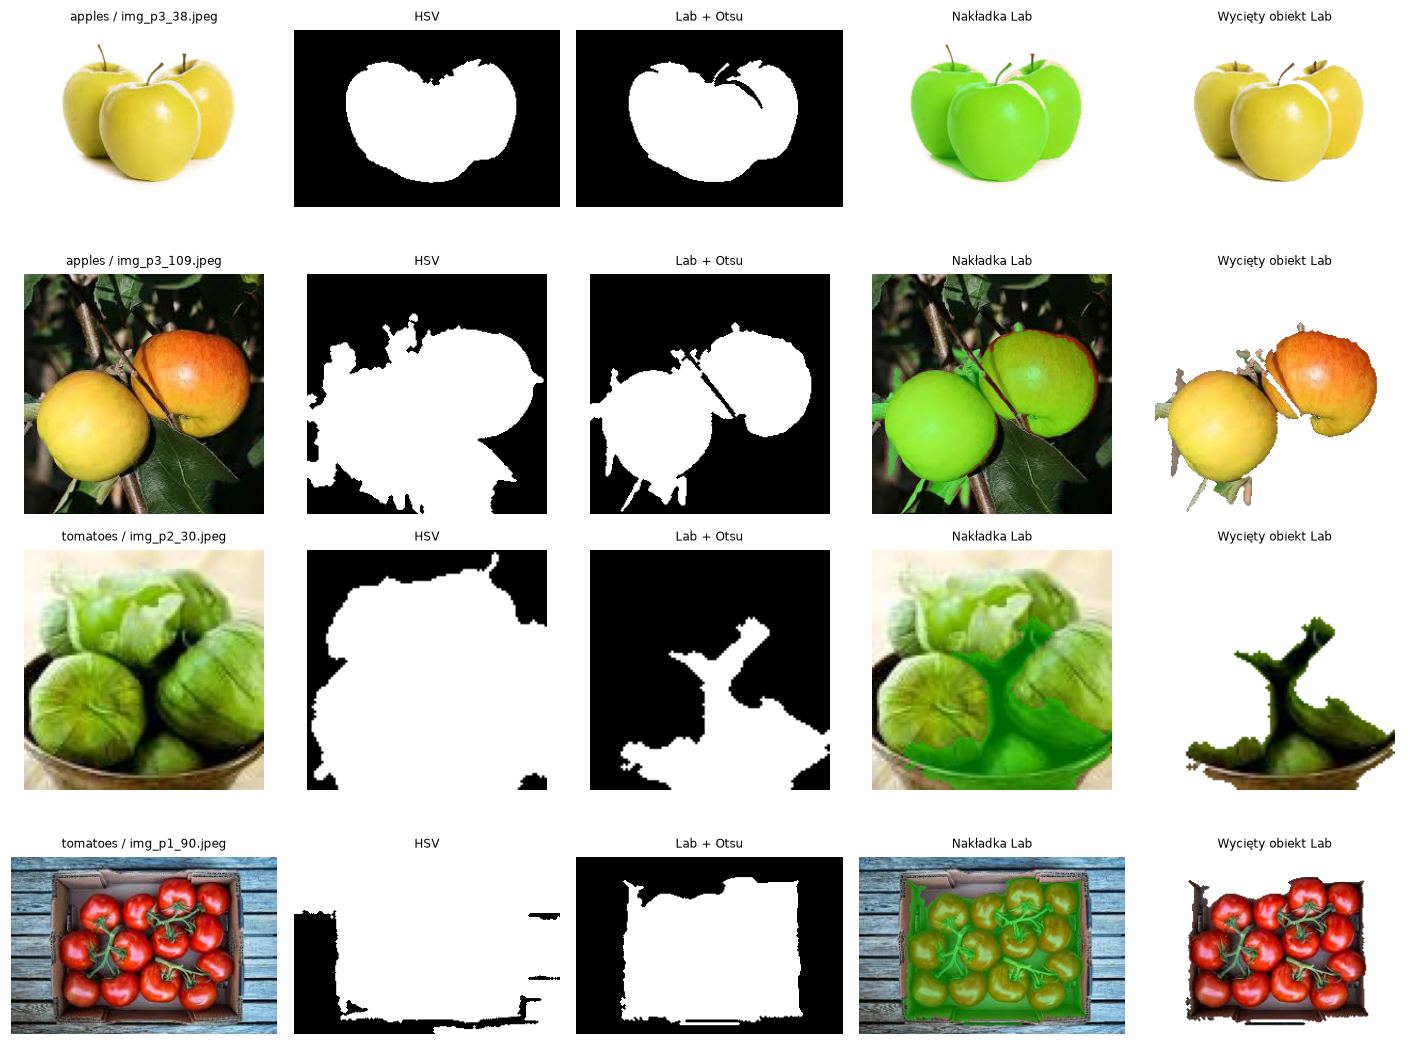

In [4]:
def clean_mask(mask):
    mask = mask.astype(np.uint8)*255
    k = max(3, int(round(min(mask.shape)*.012)) | 1)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k,k))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    out = np.zeros_like(mask)
    if contours: cv2.drawContours(out, [max(contours,key=cv2.contourArea)], -1, 255, -1)
    return out > 0

def segment(rgb, method='lab'):
    # Wspólna skala robocza ogranicza koszt i stabilizuje morfologię.
    h,w = rgb.shape[:2]
    scale = min(1, 384/max(h,w))
    small = cv2.resize(rgb, (max(1,round(w*scale)),max(1,round(h*scale))))
    if method == 'hsv':
        hsv = cv2.cvtColor(small, cv2.COLOR_RGB2HSV)
        raw = (hsv[:,:,1] > 55) & (hsv[:,:,2] > 35)
    else:
        lab = cv2.cvtColor(small, cv2.COLOR_RGB2LAB).astype(np.float32)
        b = max(1, round(min(lab.shape[:2])*.04))
        border = np.concatenate([lab[:b].reshape(-1,3), lab[-b:].reshape(-1,3),
                                 lab[:,:b].reshape(-1,3), lab[:,-b:].reshape(-1,3)])
        background = np.median(border, axis=0)
        distance = np.linalg.norm(lab-background, axis=2)
        distance = np.uint8(np.clip(distance,0,255))
        _, raw = cv2.threshold(distance,0,255,cv2.THRESH_BINARY+cv2.THRESH_OTSU)
        raw = raw > 0
    cleaned = clean_mask(raw)
    return cv2.resize(cleaned.astype(np.uint8),(w,h),interpolation=cv2.INTER_NEAREST).astype(bool)

def show_segmentation(frame, filename):
    fig, axes = plt.subplots(len(frame),5,figsize=(13,2.5*len(frame)),squeeze=False)
    for axs, row in zip(axes,frame.itertuples()):
        rgb = read_rgb(row.path); hsv = segment(rgb,'hsv'); mask = segment(rgb,'lab')
        overlay = rgb.copy(); overlay[mask] = (.6*rgb[mask]+.4*np.array([0,255,0])).astype(np.uint8)
        cutout = np.full_like(rgb,255); cutout[mask] = rgb[mask]
        for ax, im, title in zip(axs,[rgb,hsv,mask,overlay,cutout],
                                [row.label+' / '+Path(row.path).name,'HSV','Lab + Otsu','Nakładka Lab','Wycięty obiekt Lab']):
            ax.imshow(im,cmap='gray' if im.ndim==2 else None); ax.set_title(title,fontsize=8); ax.axis('off')
    plt.tight_layout(); plt.savefig(OUT/filename,bbox_inches='tight'); plt.show()
show_segmentation(examples.groupby('label',sort=False).head(2),'segmentation_examples.png')


## 4. Diagnostyka masek na całym train
Udział maski i kontakt z brzegiem służą do wykrywania podejrzanych wyników. Nie mierzą dokładności segmentacji. Porównanie metod nie zastępuje ręcznej anotacji.

hsv_fraction                lab_fraction                      \
                  min    median  max          min    median       max   
label                                                                   
apples       0.000000  0.510242  1.0     0.018300  0.322657  0.762104   
tomatoes     0.062014  0.778553  1.0     0.008217  0.286894  0.759500   

         agreement_iou                      
                   min    median       max  
label                                       
apples             0.0  0.849228  0.997138  
tomatoes           0.0  0.379515  0.992835

Maski Lab wymagające przeglądu: 40 / 294


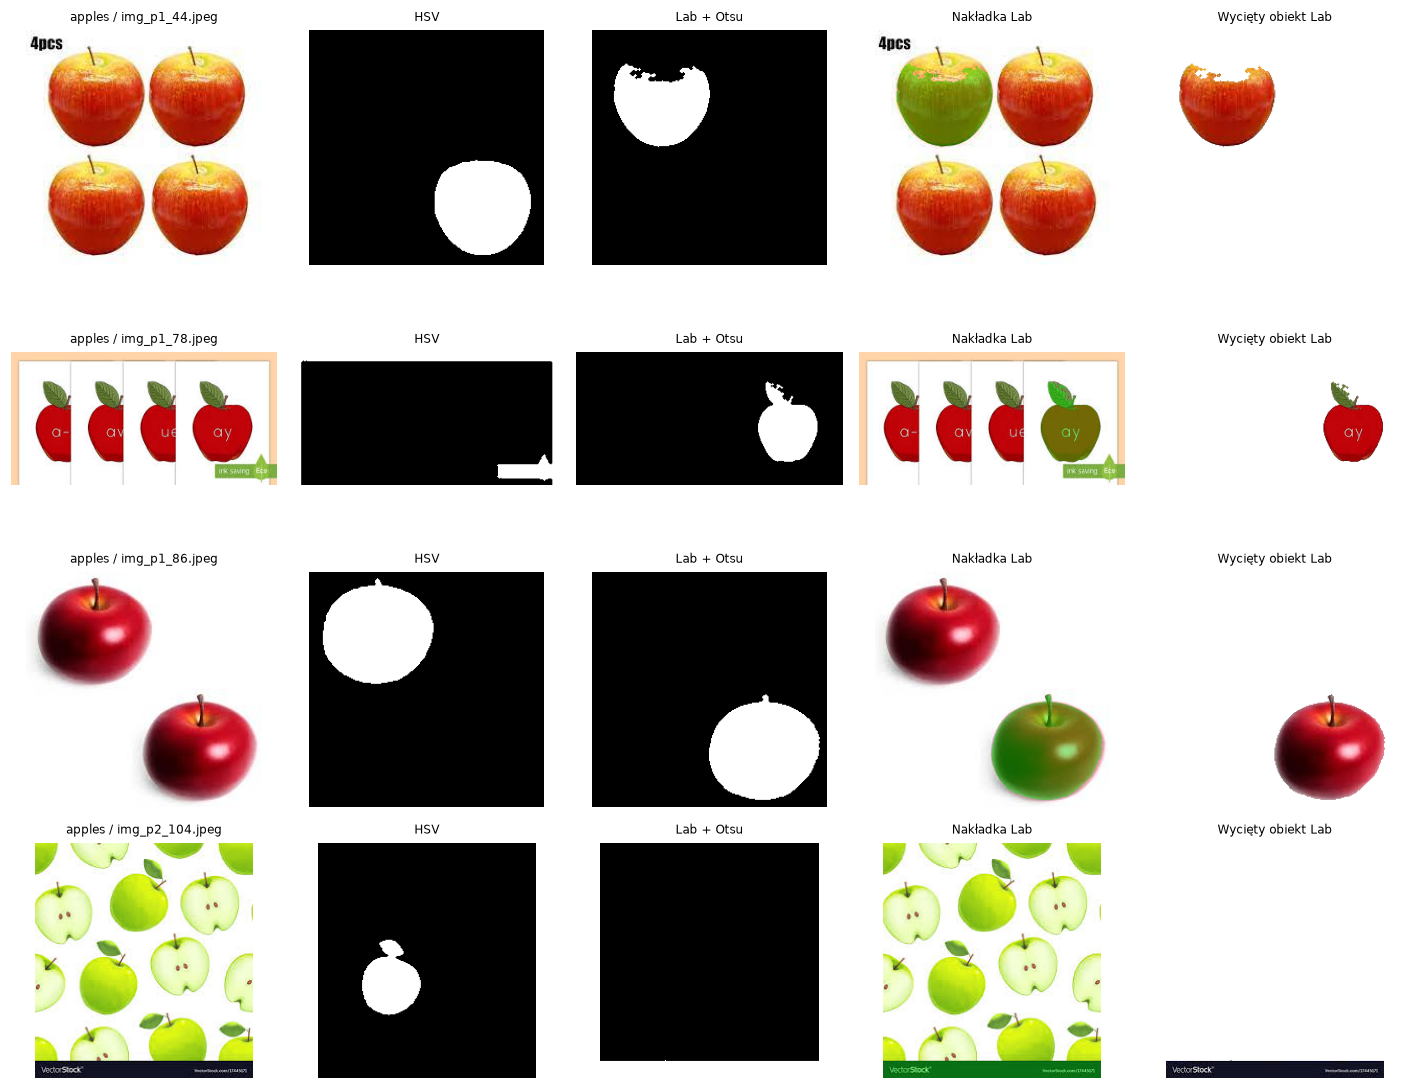

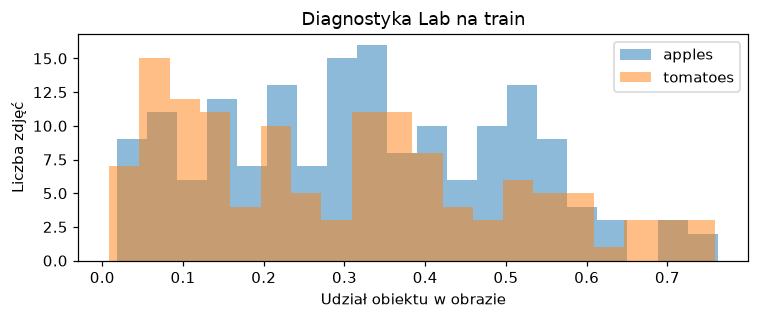

In [5]:
stats=[]
for row in train.itertuples():
    rgb=read_rgb(row.path)
    a,b=segment(rgb,'hsv'),segment(rgb,'lab')
    edge=np.concatenate([b[0],b[-1],b[:,0],b[:,-1]])
    stats.append(dict(path=row.path,label=row.label,hsv_fraction=a.mean(),lab_fraction=b.mean(),
                      border_fraction=edge.mean(),agreement_iou=(a&b).sum()/max(1,(a|b).sum())))
masks=pd.DataFrame(stats)
display(masks.groupby('label').agg({'hsv_fraction':['min','median','max'],
                                  'lab_fraction':['min','median','max'],
                                  'agreement_iou':['min','median','max']}))
masks['flag']=(masks.lab_fraction<.05)|(masks.lab_fraction>.90)|(masks.border_fraction>.25)
print('Maski Lab wymagające przeglądu:',int(masks.flag.sum()),'/',len(masks))
masks.to_csv(OUT/'segmentation_diagnostics_train.csv',index=False)
# Największa rozbieżność metod: automatyczny wybór trudnych przypadków bez testu.
hard=masks.nsmallest(4,'agreement_iou')
show_segmentation(hard,'segmentation_difficult.png')
fig,ax=plt.subplots(figsize=(7,3))
for label,g in masks.groupby('label'): ax.hist(g.lab_fraction,bins=20,alpha=.5,label=label)
ax.set(xlabel='Udział obiektu w obrazie',ylabel='Liczba zdjęć',title='Diagnostyka Lab na train'); ax.legend(); plt.tight_layout(); plt.show()


## 5. Wnioski i dalszy eksperyment
- Segmentacja daje maskę do pomiaru pola, obwodu, kolistości, proporcji oraz koloru samego owocu. Kolor tła nie powinien wtedy dominować cech.
- HSV może pomijać jasne fragmenty owocu i przejmować kolorowe tło. Lab zakłada reprezentatywny kolor brzegu; obiekt dotykający brzegu lub niejednolite tło może ten warunek naruszać.
- Siatki wyżej pokazują wyniki i największe rozbieżności, nie dowód poprawności. Do wyboru metody warto ręcznie oznaczyć maski dla reprezentatywnego podzbioru train i porównać IoU/Dice.
- Nazwy `img_p…` mogą kodować serie ujęć. Bez dokumentacji nie wiemy, czy train i test zawierają różne zdjęcia tego samego owocu. Kontrola identycznych pikseli nie wykrywa takiego przecieku.
- Kolejny krok: porównać klasyfikator na cechach całego zdjęcia i na cechach maski, walidując wyłącznie na train (grupując po obiekcie/serii, jeśli uda się je ustalić). Test zachować do końcowej oceny. Nie wybieramy segmentacji na podstawie wyniku testowego.

## Wyniki wykonanej analizy
- **391 obrazów: 294 train i 97 test**, brak błędów odczytu. Rozmiary są zróżnicowane.
- **23 nadmiarowe kopie identycznych obrazów** w całym zbiorze. **26 plików** należy do grup identycznych pikselowo obrazów występujących w obu splitach. Przed oceną klasyfikatora trzeba rozwiązać ten przeciek; oryginalnych plików nie zmieniono.
- Dane obejmują fotografie pojedynczych i wielu owoców, ilustracje, wzory i obrazy z tekstem. Założenie jednego głównego owocu nie jest spełnione w całym zbiorze.
- Na przykładach Lab oddziela jabłka od białego tła i część jabłek od liści. Zielone pomidory są wycinane niepoprawnie; skrzynka zostaje razem z pomidorami. Przy wielu rozłącznych owocach największy komponent zachowuje tylko jeden.
- Heurystyka oznaczyła **40/294** masek Lab do przeglądu. To liczba ostrzeżeń, nie liczba wszystkich błędów.
- Wniosek: segmentacja jest sensownym eksperymentem wstępnym, ale ten prosty wariant nie nadaje się jeszcze do automatycznego przetwarzania całego datasetu. Najpierw należy określić, czy chcemy maskę wszystkich owoców czy pojedynczego obiektu, i zweryfikować ją na ręcznie oznaczonych przykładach train.


# 6. Tekstury i klasyfikacja
Korzystamy z zapisanych masek `segmented_dataset/masks`, bez ponownej segmentacji. Cechy opisują wyłącznie jasność i jej lokalne zmiany — bez koloru, wielkości maski i tła. Porównamy LBP, GLCM i połączenie obu. Brak masek wzorcowych oznacza, że błędna segmentacja może dostarczać tekstury tła zamiast owocu.

**Maskowanie jest istotne:** nie liczymy tekstury na prostokątnym wycinku z czarnym tłem. Dla LBP całe sąsiedztwo musi leżeć wewnątrz maski, a dla GLCM oba piksele pary muszą należeć do maski. Zachowujemy oryginalną rozdzielczość; różna skala owoców pozostaje ograniczeniem.

In [6]:
from skimage.feature import local_binary_pattern, graycoprops
from sklearn.model_selection import StratifiedGroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (balanced_accuracy_score, accuracy_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)
import json

SEG = ROOT / 'segmented_dataset'
manifest = pd.read_csv(SEG / 'manifest.csv')

def texture_features(rgb, mask):
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    feats = {}
    # Uniform LBP: histogram 10 kategorii dla 8 sąsiadów.
    interior = cv2.erode(mask.astype(np.uint8), np.ones((3,3), np.uint8),
                         borderType=cv2.BORDER_CONSTANT, borderValue=0).astype(bool)
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    hist = np.bincount(lbp[interior].astype(int), minlength=10).astype(float)
    hist = hist / hist.sum() if hist.sum() else np.full(10, np.nan)
    feats.update({f'lbp_{i}':v for i,v in enumerate(hist)})
    # Symetryczna GLCM, 16 poziomów, odległości 1/2 i cztery kierunki.
    q = (gray.astype(np.uint16)*16//256).astype(np.uint8)
    props = ['contrast','dissimilarity','homogeneity','ASM','energy','correlation']
    for d in (1,2):
        values = {prop:[] for prop in props}
        for dy,dx in ((0,d),(d,0),(d,d),(d,-d)):
            h,w=mask.shape
            ya=slice(max(0,-dy),h-max(0,dy)); yb=slice(max(0,dy),h-max(0,-dy))
            xa=slice(max(0,-dx),w-max(0,dx)); xb=slice(max(0,dx),w-max(0,-dx))
            valid = mask[ya,xa] & mask[yb,xb]
            if not valid.any(): continue
            a,b=q[ya,xa][valid],q[yb,xb][valid]
            mat=np.bincount(a.astype(int)*16+b,minlength=256).reshape(16,16).astype(float)
            mat=mat+mat.T; mat/=mat.sum()
            for prop in props:
                values[prop].append(float(graycoprops(mat[:,:,None,None],prop)[0,0]))
        for prop,v in values.items():
            feats[f'glcm_d{d}_{prop}_mean']=np.mean(v) if v else np.nan
            feats[f'glcm_d{d}_{prop}_std']=np.std(v) if v else np.nan
    return feats, int(interior.sum())

records=[]
for row in manifest.itertuples():
    source=DATA / row.source
    rgb=read_rgb(source)
    with Image.open(SEG / row.mask) as im: mask=np.array(im)>0
    features, n_interior=texture_features(rgb,mask)
    records.append(dict(source=row.source,split=row.split,label=row.label,
                        pixel_hash=hashlib.sha256(str(rgb.shape).encode()+rgb.tobytes()).hexdigest(),
                        interior_pixels=n_interior,**features))
textures=pd.DataFrame(records)
feature_cols=[c for c in textures if c.startswith(('lbp_','glcm_'))]
textures.to_csv(OUT/'texture_features.csv',index=False)
print('Liczba cech tekstury:',len(feature_cols))
print('Maski bez pełnego sąsiedztwa LBP:',int((textures.interior_pixels==0).sum()))
display(textures.groupby(['split','label']).size().rename('images').to_frame())


Liczba cech tekstury: 34
Maski bez pełnego sąsiedztwa LBP: 0


images
split label           
test  apples        54
      tomatoes      43
train apples       164
      tomatoes     130

## 6.1. Wizualizacja tekstury
Białe tło poniżej służy tylko prezentacji. Histogram LBP i mapa lokalnych wzorców obejmują wyłącznie piksele z pełnym sąsiedztwem wewnątrz maski. Przykłady wybieramy z train.

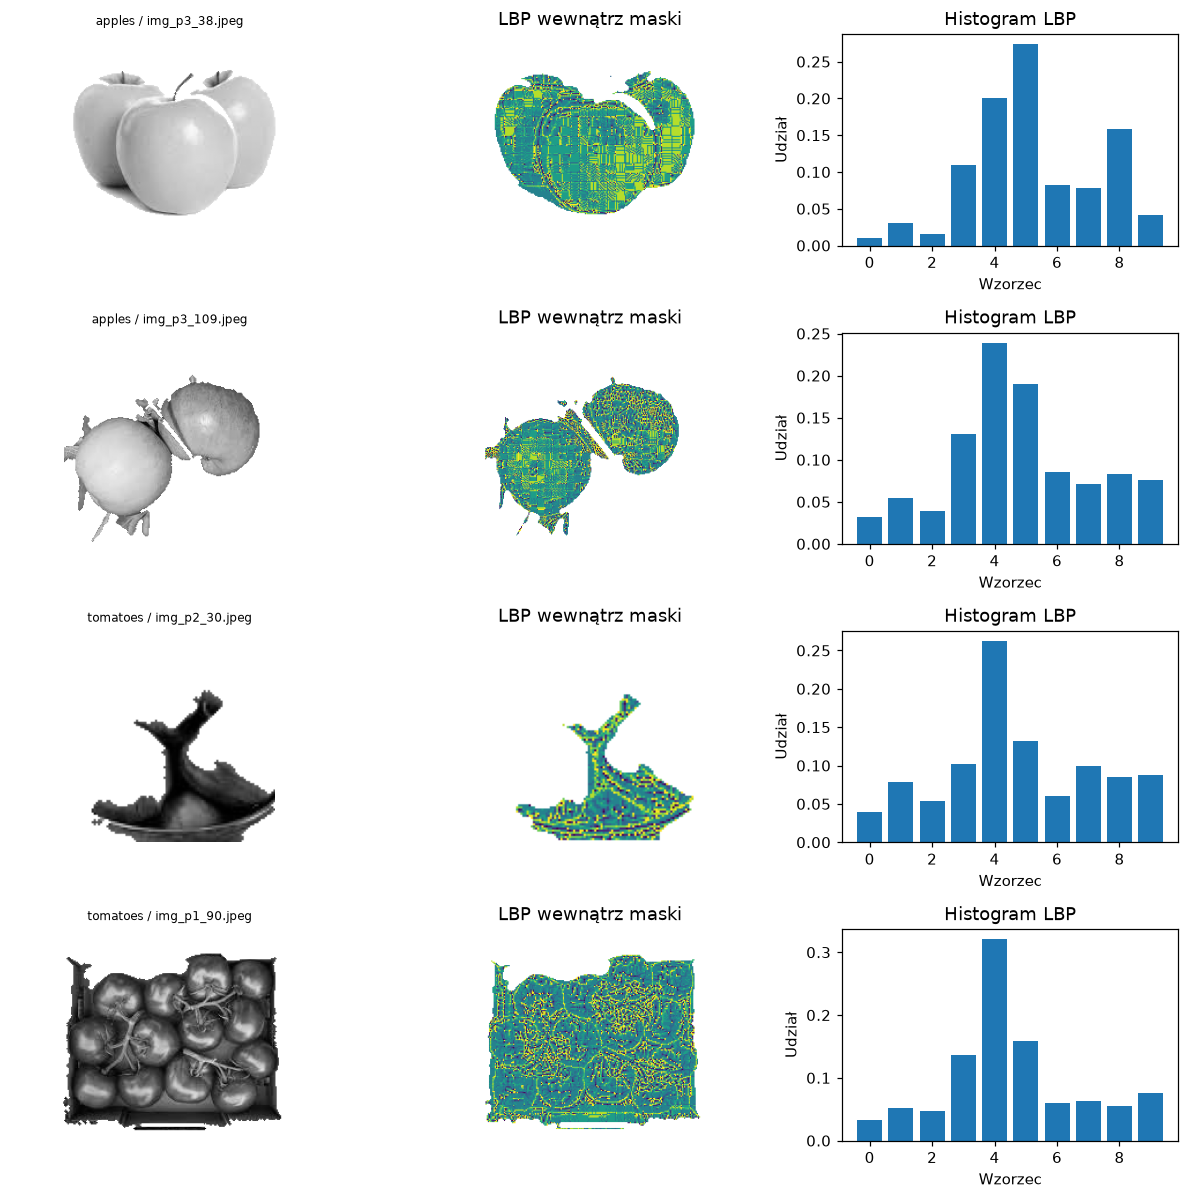

In [7]:
fig,axes=plt.subplots(4,3,figsize=(11,11))
selected=pd.concat([g.sample(2,random_state=SEED) for _,g in textures[textures.split=='train'].groupby('label')])
for axs,row in zip(axes,selected.itertuples()):
    rgb=read_rgb(DATA/row.source)
    with Image.open(SEG/'masks'/(row.source+'.png')) as im: mask=np.array(im)>0
    gray=cv2.cvtColor(rgb,cv2.COLOR_RGB2GRAY)
    interior=cv2.erode(mask.astype(np.uint8),np.ones((3,3),np.uint8),borderType=cv2.BORDER_CONSTANT,borderValue=0)>0
    lbp=local_binary_pattern(gray,8,1,'uniform')
    axs[0].imshow(np.ma.array(gray,mask=~mask),cmap='gray',vmin=0,vmax=255)
    axs[0].set_title(row.label+' / '+Path(row.source).name,fontsize=8)
    axs[1].imshow(np.ma.array(lbp,mask=~interior),cmap='viridis',vmin=0,vmax=9)
    axs[1].set_title('LBP wewnątrz maski')
    for ax in axs[:2]: ax.axis('off')
    axs[2].bar(range(10),[getattr(row,f'lbp_{i}') for i in range(10)])
    axs[2].set(title='Histogram LBP',xlabel='Wzorzec',ylabel='Udział')
plt.tight_layout(); plt.savefig(OUT/'texture_examples.png',bbox_inches='tight'); plt.show()


## 6.2. Podział i dobór klasyfikatora
Usuwamy nadmiarowe identyczne obrazy osobno w train i test, a z testu także wszystkie obrazy identyczne z train. Nie usuwamy zdjęć na podstawie jakości maski: mierzymy cały potok, łącznie z jego błędami. Brakujące cechy imputujemy medianą wyliczoną wyłącznie na foldzie treningowym.

Parametry SVM i rodzaj cech wybieramy przez 5-fold walidację wyłącznie na train. Grupowanie po hashu pikseli zabezpiecza przed identycznymi obrazami w foldach; nie gwarantuje rozdzielenia różnych zdjęć tego samego owocu. Test wykorzystujemy raz dla wybranego wariantu. Punktem odniesienia jest przewidywanie najczęstszej klasy.

Kontrola spójności etykiet obejmuje cały zbiór: wszystkie grupy identycznych obrazów ze sprzecznymi etykietami wyłączamy przed eksperymentem, bez zgadywania poprawnej klasy. Jest to jawna korekta jakości danych, wykorzystująca etykiety train i test, a nie dobór parametrów modelu.

Sprzecznie opisane obrazy: 2 w grupach: 1


,source,label
50,test/apples/img_p3_79.jpeg,apples
277,train/tomatoes/img_p1_28.jpeg,tomatoes


Po usunięciu duplikatów: train = 283 test = 84


label,apples,tomatoes
split,,
test,44,40
train,156,127


,features,cv_balanced_accuracy,cv_std,params
2,LBP + GLCM,0.711971,0.032856,"{'svm__C': 100, 'svm__gamma': 'scale'}"
1,GLCM,0.700265,0.054404,"{'svm__C': 100, 'svm__gamma': 'scale'}"
0,LBP,0.688857,0.077007,"{'svm__C': 10, 'svm__gamma': 'scale'}"


,model,accuracy,balanced_accuracy,f1_macro
0,Dummy: najczęstsza klasa,0.52381,0.500000,0.343750
1,SVM / LBP + GLCM,0.77381,0.771591,0.772228


              precision    recall  f1-score   support

      apples       0.77      0.82      0.79        44
    tomatoes       0.78      0.72      0.75        40

    accuracy                           0.77        84
   macro avg       0.77      0.77      0.77        84
weighted avg       0.77      0.77      0.77        84



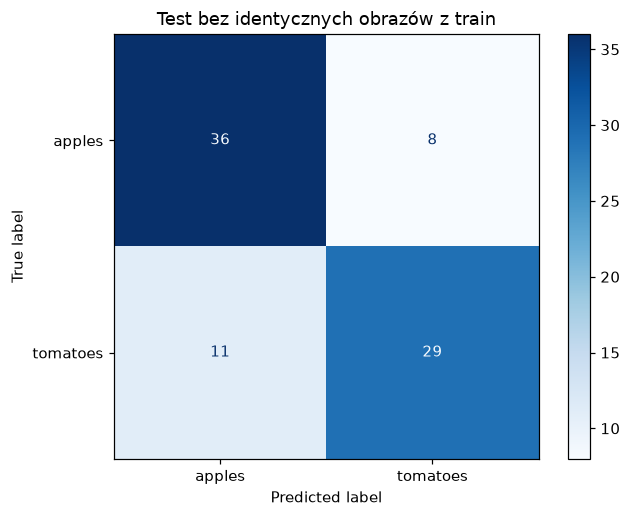

Wybrany wariant: LBP + GLCM | Parametry: {'svm__C': 100, 'svm__gamma': 'scale'}


In [8]:
conflicts=textures.groupby('pixel_hash').label.nunique()
conflict_hashes=set(conflicts[conflicts>1].index)
conflict_rows=textures[textures.pixel_hash.isin(conflict_hashes)]
print('Sprzecznie opisane obrazy:',len(conflict_rows),'w grupach:',len(conflict_hashes))
display(conflict_rows[['source','label']])
conflict_rows.to_csv(OUT/'texture_label_conflicts.csv',index=False)
clean=textures[~textures.pixel_hash.isin(conflict_hashes)]
tr=clean[clean.split=='train'].drop_duplicates('pixel_hash').copy()
te=clean[clean.split=='test'].drop_duplicates('pixel_hash').copy()
te=te[~te.pixel_hash.isin(tr.pixel_hash)].copy()
assert not set(tr.pixel_hash)&set(te.pixel_hash)

print('Po usunięciu duplikatów: train =',len(tr),'test =',len(te))
display(pd.crosstab(pd.concat([tr,te])['split'],pd.concat([tr,te])['label']))
sets={'LBP':[c for c in feature_cols if c.startswith('lbp_')],
      'GLCM':[c for c in feature_cols if c.startswith('glcm_')],
      'LBP + GLCM':feature_cols}
cv=list(StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=SEED).split(tr,tr.label,tr.pixel_hash))
searches={}; scores=[]
for name,cols in sets.items():
    pipe=Pipeline([('impute',SimpleImputer(strategy='median',keep_empty_features=True)),
                   ('scale',StandardScaler()),('svm',SVC(class_weight='balanced'))])
    search=GridSearchCV(pipe,{'svm__C':[.1,1,10,100], 'svm__gamma':['scale',.01,.1]},
                        scoring='balanced_accuracy',cv=cv,n_jobs=1)
    search.fit(tr[cols],tr.label)
    searches[name]=search
    scores.append(dict(features=name,cv_balanced_accuracy=search.best_score_,
                       cv_std=search.cv_results_['std_test_score'][search.best_index_],params=str(search.best_params_)))
comparison=pd.DataFrame(scores).sort_values('cv_balanced_accuracy',ascending=False)
display(comparison)
best_name=comparison.iloc[0]['features']; best=searches[best_name]; cols=sets[best_name]
pred=best.predict(te[cols])
dummy=DummyClassifier(strategy='most_frequent').fit(tr[cols],tr.label)
baseline=dummy.predict(te[cols])
results=pd.DataFrame([dict(model='Dummy: najczęstsza klasa',accuracy=accuracy_score(te.label,baseline),
                           balanced_accuracy=balanced_accuracy_score(te.label,baseline),f1_macro=f1_score(te.label,baseline,average='macro')),
                      dict(model='SVM / '+best_name,accuracy=accuracy_score(te.label,pred),
                           balanced_accuracy=balanced_accuracy_score(te.label,pred),f1_macro=f1_score(te.label,pred,average='macro'))])
display(results)
print(classification_report(te.label,pred,zero_division=0))
ConfusionMatrixDisplay.from_predictions(te.label,pred,cmap='Blues'); plt.title('Test bez identycznych obrazów z train'); plt.tight_layout()
plt.savefig(OUT/'texture_confusion_matrix.png',bbox_inches='tight'); plt.show()
comparison.to_csv(OUT/'texture_cv_results.csv',index=False)
results.to_csv(OUT/'texture_test_metrics.csv',index=False)
predictions=te[['source','label','interior_pixels']].copy(); predictions['prediction']=pred
predictions.to_csv(OUT/'texture_test_predictions.csv',index=False)
print('Wybrany wariant:',best_name,'| Parametry:',best.best_params_)


## 6.3. Interpretacja
Wynik testowy ocenia połączenie obecnej segmentacji i tekstury, a nie jakość samych masek. LBP opisuje lokalne wzorce jasności, GLCM kontrast i uporządkowanie sąsiadujących pikseli. Żadna z tych cech nie identyfikuje pomidora na podstawie koloru czy pełnego kształtu.

Błędna maska nadal może dać cechy tła; puste maski otrzymują imputowane cechy i nie dostarczają informacji o owocu. Mały test i możliwe podobne ujęcia ograniczają wiarygodność wyniku. Poprawa masek oraz porównanie z modelem na oryginalnych zdjęciach pozostają osobnymi eksperymentami; nie dostrajamy ich do tego testu.

### Wynik wykonanego eksperymentu
Po kontroli danych: **283 obrazów treningowych i 84 testowe**. Wyłączono jedną grupę dwóch identycznych obrazów ze sprzecznymi etykietami.

Najlepszy wariant walidacyjny: **LBP + GLCM, SVM RBF**, C=100, gamma=scale. Średnia balanced accuracy z 5 foldów: **71,2%**, odchylenie między foldami: **3,3 punktu procentowego** (nie jest to przedział ufności).

Na teście: **accuracy 77,4% (65/84)**, **balanced accuracy 77,2%**, **macro F1 77,2%**. Model najczęstszej klasy: accuracy 52,4%, balanced accuracy 50,0%.

Tekstury dostarczają użytecznego sygnału mimo niedoskonałych masek. Wynik nie dowodzi jednak, że model rozpoznaje wyłącznie powierzchnię owocu: błędne maski mogą zawierać tło, gałęzie i opakowania. Różna skala obrazów i podobne ujęcia również mogą wpływać na ocenę.
